<a href="https://colab.research.google.com/github/swetha-off/DSA0302-NLP/blob/main/ASSIGNMENT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total utterances: 20000

WORD COUNT DETAILS
Total tokens: 145781
Total types: 65
Unique word forms: 65
Unique lemmas: 64

TOKENIZATION EXAMPLES
Vellore: ['vellore']
vellore: ['vellore']
Time: ['6:30']
Punctuation: ['ticket', 'please']

Vocabulary under method 1: 4
Vocabulary under method 2: 6


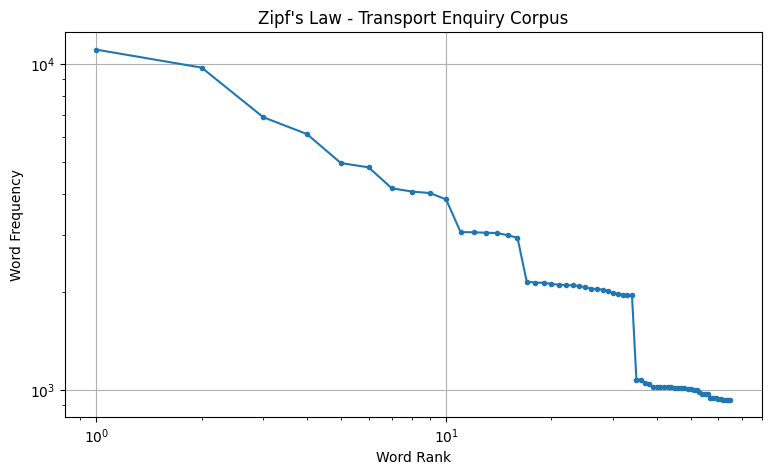


TOP 10 FREQUENT WORDS
[('to', 11101), ('the', 9777), ('is', 6887), ('i', 6113), ('from', 4981), ('bus', 4832), ('my', 4165), ('ticket', 4072), ('a', 4028), ('at', 3851)]

VOCABULARY AND UNK ANALYSIS

Threshold: 1
Vocabulary size: 65
UNK tokens: 0
UNK percentage: 0.0 %

Threshold: 2
Vocabulary size: 65
UNK tokens: 0
UNK percentage: 0.0 %

Threshold: 3
Vocabulary size: 65
UNK tokens: 0
UNK percentage: 0.0 %

Threshold: 5
Vocabulary size: 65
UNK tokens: 0
UNK percentage: 0.0 %

DATASET SPLIT
Training: 16000
Development: 2000
Testing: 2000

OUT OF VOCABULARY ANALYSIS
Development tokens: 14530
OOV tokens: 0
OOV rate: 0.0 %


In [1]:

import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Fixed random seed
random.seed(42)
np.random.seed(42)

# 1. Create synthetic transport enquiry corpus
templates = [
    "I want to book two tickets to {}",
    "What is the bus fare from {} to {}",
    "Tell me the train timing from {} to {}",
    "Is the bus available at {}",
    "Please cancel my ticket to {}",
    "I need a return ticket from {} to {}",
    "When will the next bus arrive at {}",
    "How can I get a refund for my ticket",
    "Is there a direct train to {}",
    "Please tell me the platform number",
    "I want to travel from {} to {}",
    "What is the departure time of the train",
    "Are tickets available for tomorrow",
    "Please book a seat for me",
    "Where is the nearest bus stand",
    "I want to check my ticket status",
    "Does this bus stop at {}",
    "What is the arrival time at {}",
    "Can I change my travel date",
    "How much is the return fare from {} to {}"
]

cities = ["Chennai", "Vellore", "Bangalore", "Madurai",
          "Coimbatore", "Salem", "Trichy", "Tirupati"]

utterances = []

for i in range(20000):
    template = random.choice(templates)
    needed = template.count("{}")
    values = random.choices(cities, k=needed)
    sentence = template.format(*values)
    utterances.append(sentence)

print("Total utterances:", len(utterances))

# 2. Tokenization
def tokenize(text):
    return re.findall(
        r"\d{1,2}:\d{2}|\d+(?:\.\d+)?|[a-zA-Z]+(?:'[a-z]+)?",
        text.lower()
    )

tokens = [tokenize(s) for s in utterances]

# 3. Count tokens, types, word forms and lemmas
all_tokens = [word for sentence in tokens for word in sentence]

token_count = len(all_tokens)
word_forms = set(all_tokens)
type_count = len(word_forms)

# Simple rule-based lemmatization
def lemmatize(word):
    if len(word) > 4 and word.endswith("ies"):
        return word[:-3] + "y"
    if len(word) > 4 and word.endswith("ing"):
        return word[:-3]
    if len(word) > 3 and word.endswith("s") and not word.endswith("ss"):
        return word[:-1]
    return word

lemmas = set(lemmatize(w) for w in all_tokens)

print("\nWORD COUNT DETAILS")
print("Total tokens:", token_count)
print("Total types:", type_count)
print("Unique word forms:", len(word_forms))
print("Unique lemmas:", len(lemmas))

# 4. Show tokenization decisions
print("\nTOKENIZATION EXAMPLES")
print("Vellore:", tokenize("Vellore"))
print("vellore:", tokenize("vellore"))
print("Time:", tokenize("6:30"))
print("Punctuation:", tokenize("ticket, please!"))

# Compare two tokenization methods
method1 = set(tokenize("Vellore vellore 6:30 ticket, please!"))

def alternate_tokenize(text):
    return re.findall(r"[a-zA-Z]+|\d", text.lower())

method2 = set(alternate_tokenize(
    "Vellore vellore 6:30 ticket, please!"
))

print("\nVocabulary under method 1:", len(method1))
print("Vocabulary under method 2:", len(method2))

# 5. Zipf's Law
frequency = Counter(all_tokens)
ranked = frequency.most_common()

ranks = range(1, len(ranked) + 1)
frequencies = [count for word, count in ranked]

plt.figure(figsize=(9, 5))
plt.loglog(ranks, frequencies, marker='.')
plt.xlabel("Word Rank")
plt.ylabel("Word Frequency")
plt.title("Zipf's Law - Transport Enquiry Corpus")
plt.grid(True)
plt.show()

print("\nTOP 10 FREQUENT WORDS")
print(frequency.most_common(10))

# 6. Vocabulary with unknown word thresholds
print("\nVOCABULARY AND UNK ANALYSIS")

for threshold in [1, 2, 3, 5]:
    vocab = {
        word for word, count in frequency.items()
        if count >= threshold
    }

    unknown_count = sum(
        count for word, count in frequency.items()
        if count < threshold
    )

    unk_percentage = (unknown_count / token_count) * 100

    print("\nThreshold:", threshold)
    print("Vocabulary size:", len(vocab))
    print("UNK tokens:", unknown_count)
    print("UNK percentage:", round(unk_percentage, 2), "%")

# 7. Split corpus into training, development and test
indices = list(range(len(tokens)))
random.shuffle(indices)

train_end = int(0.8 * len(indices))
dev_end = int(0.9 * len(indices))

train_indices = indices[:train_end]
dev_indices = indices[train_end:dev_end]
test_indices = indices[dev_end:]

train_data = [tokens[i] for i in train_indices]
dev_data = [tokens[i] for i in dev_indices]
test_data = [tokens[i] for i in test_indices]

print("\nDATASET SPLIT")
print("Training:", len(train_data))
print("Development:", len(dev_data))
print("Testing:", len(test_data))

# 8. Calculate OOV rate
train_vocab = set(
    word for sentence in train_data for word in sentence
)

dev_tokens = [word for sentence in dev_data for word in sentence]

oov_words = [word for word in dev_tokens if word not in train_vocab]

oov_rate = len(oov_words) / len(dev_tokens) * 100

print("\nOUT OF VOCABULARY ANALYSIS")
print("Development tokens:", len(dev_tokens))
print("OOV tokens:", len(oov_words))
print("OOV rate:", round(oov_rate, 2), "%")


**TASK** **2**

In [2]:

import random
import re
import numpy as np
from collections import Counter, defaultdict

# Fixed random seed
random.seed(42)
np.random.seed(42)

# 1. Generate the same transport enquiry corpus
templates = [
    "I want to book two tickets to {}",
    "What is the bus fare from {} to {}",
    "Tell me the train timing from {} to {}",
    "Is the bus available at {}",
    "Please cancel my ticket to {}",
    "I need a return ticket from {} to {}",
    "When will the next bus arrive at {}",
    "How can I get a refund for my ticket",
    "Is there a direct train to {}",
    "Please tell me the platform number",
    "I want to travel from {} to {}",
    "What is the departure time of the train",
    "Are tickets available for tomorrow",
    "Please book a seat for me",
    "Where is the nearest bus stand",
    "I want to check my ticket status",
    "Does this bus stop at {}",
    "What is the arrival time at {}",
    "Can I change my travel date",
    "How much is the return fare from {} to {}"
]

cities = ["Chennai", "Vellore", "Bangalore", "Madurai",
          "Coimbatore", "Salem", "Trichy", "Tirupati"]

corpus = []

for i in range(20000):
    template = random.choice(templates)
    values = random.choices(cities, k=template.count("{}"))
    corpus.append(template.format(*values))

def tokenize(text):
    return re.findall(r"\d{1,2}:\d{2}|\d+|[a-zA-Z]+", text.lower())

data = [tokenize(s) for s in corpus]

# 2. Split data into 80%, 10%, 10%
indices = list(range(len(data)))
random.shuffle(indices)

train_end = int(0.8 * len(indices))
dev_end = int(0.9 * len(indices))

train_data = [data[i] for i in indices[:train_end]]
dev_data = [data[i] for i in indices[train_end:dev_end]]
test_data = [data[i] for i in indices[dev_end:]]

# 3. Build unigram, bigram and trigram counts
unigram = Counter()
bigram = Counter()
trigram = Counter()

bigram_context = Counter()
trigram_context = Counter()

for sentence in train_data:
    words = ["<s>"] + sentence + ["</s>"]

    unigram.update(sentence + ["</s>"])

    for i in range(len(words) - 1):
        bigram[(words[i], words[i+1])] += 1
        bigram_context[words[i]] += 1

    padded = ["<s>", "<s>"] + sentence + ["</s>"]

    for i in range(len(padded) - 2):
        trigram[tuple(padded[i:i+3])] += 1
        trigram_context[tuple(padded[i:i+2])] += 1

total_words = sum(unigram.values())

# 4. Maximum Likelihood Estimation
def unigram_probability(word):
    return unigram[word] / total_words

def bigram_probability(w1, w2):
    if bigram_context[w1] == 0:
        return 0
    return bigram[(w1, w2)] / bigram_context[w1]

def trigram_probability(w1, w2, w3):
    context = (w1, w2)
    if trigram_context[context] == 0:
        return 0
    return trigram[(w1, w2, w3)] / trigram_context[context]

print("UNIGRAM EXAMPLE")
print("P(bus) =", unigram_probability("bus"))

print("\nBIGRAM EXAMPLE")
print("P(bus | the) =", bigram_probability("the", "bus"))

print("\nTRIGRAM EXAMPLE")
print("P(bus | the next) =",
      trigram_probability("the", "next", "bus"))

# 5. Calculate sentence probability
def calculate_probability(sentence, model):
    words = tokenize(sentence)
    factors = []

    if model == "unigram":
        for word in words + ["</s>"]:
            factors.append(unigram_probability(word))

    elif model == "bigram":
        padded = ["<s>"] + words + ["</s>"]
        for i in range(len(padded) - 1):
            factors.append(
                bigram_probability(padded[i], padded[i+1])
            )

    elif model == "trigram":
        padded = ["<s>", "<s>"] + words + ["</s>"]
        for i in range(len(padded) - 2):
            factors.append(
                trigram_probability(
                    padded[i], padded[i+1], padded[i+2]
                )
            )

    probability = np.prod(factors)

    print("\nSentence:", sentence)
    print("Model:", model)
    print("Factors:", factors)
    print("Sentence probability:", probability)

    return probability

# 6. Calculate three sentence probabilities
calculate_probability(
    "I want to book two tickets to Chennai", "unigram"
)

calculate_probability(
    "I want to book two tickets to Chennai", "bigram"
)

calculate_probability(
    "I want to book two tickets to Chennai", "trigram"
)

# 7. Find a reasonable sentence with zero bigram probability
test_sentence = "please reserve bicycle tickets to vellore"

calculate_probability(test_sentence, "bigram")

# 8. Sparsity measurement
vocabulary = set(unigram.keys())
V = len(vocabulary)

possible_bigrams = V ** 2
possible_trigrams = V ** 3

observed_bigrams = len(bigram)
observed_trigrams = len(trigram)

print("\nMODEL SPARSITY")
print("Vocabulary size:", V)

print("Observed bigrams:", observed_bigrams)
print("Possible bigrams:", possible_bigrams)
print("Bigram sparsity (%):",
      round(observed_bigrams / possible_bigrams * 100, 4))

print("Observed trigrams:", observed_trigrams)
print("Possible trigrams:", possible_trigrams)
print("Trigram sparsity (%):",
      round(observed_trigrams / possible_trigrams * 100, 6))

# 9. Development-set unseen n-grams
dev_bigram = set()
dev_trigram = set()

for sentence in dev_data:
    words = ["<s>"] + sentence + ["</s>"]

    for i in range(len(words) - 1):
        dev_bigram.add((words[i], words[i+1]))

    padded = ["<s>", "<s>"] + sentence + ["</s>"]

    for i in range(len(padded) - 2):
        dev_trigram.add(tuple(padded[i:i+3]))

unseen_bigrams = sum(1 for x in dev_bigram if x not in bigram)
unseen_trigrams = sum(1 for x in dev_trigram if x not in trigram)

print("\nDEVELOPMENT SET UNSEEN N-GRAMS")
print("Unseen bigrams:", unseen_bigrams)
print("Total unique development bigrams:", len(dev_bigram))
print("Unseen bigram percentage:",
      round(unseen_bigrams / len(dev_bigram) * 100, 2))

print("Unseen trigrams:", unseen_trigrams)
print("Total unique development trigrams:", len(dev_trigram))
print("Unseen trigram percentage:",
      round(unseen_trigrams / len(dev_trigram) * 100, 2))

# 10. Generate sample sentences
def generate_sentence(model, max_length=15):
    result = []

    if model == "unigram":
        choices = list(unigram.keys())
        weights = list(unigram.values())

        for _ in range(max_length):
            word = random.choices(choices, weights=weights)[0]
            if word == "</s>":
                break
            result.append(word)

    elif model == "bigram":
        current = "<s>"

        for _ in range(max_length):
            candidates = [
                (word, count)
                for (previous, word), count in bigram.items()
                if previous == current
            ]

            if not candidates:
                break

            words, counts = zip(*candidates)
            word = random.choices(words, weights=counts)[0]

            if word == "</s>":
                break

            result.append(word)
            current = word

    elif model == "trigram":
        previous = "<s>"
        current = "<s>"

        for _ in range(max_length):
            candidates = [
                (key[2], count)
                for key, count in trigram.items()
                if key[0] == previous and key[1] == current
            ]

            if not candidates:
                break

            words, counts = zip(*candidates)
            word = random.choices(words, weights=counts)[0]

            if word == "</s>":
                break

            result.append(word)
            previous, current = current, word

    return " ".join(result)

print("\n10 UNIGRAM GENERATED SENTENCES")
for i in range(10):
    print(i+1, generate_sentence("unigram"))

print("\n10 BIGRAM GENERATED SENTENCES")
for i in range(10):
    print(i+1, generate_sentence("bigram"))

print("\n10 TRIGRAM GENERATED SENTENCES")
for i in range(10):
    print(i+1, generate_sentence("trigram"))


UNIGRAM EXAMPLE
P(bus) = 0.028807669985603704

BIGRAM EXAMPLE
P(bus | the) = 0.19718849840255592

TRIGRAM EXAMPLE
P(bus | the next) = 1.0

Sentence: I want to book two tickets to Chennai
Model: unigram
Factors: [0.03681231298003362, 0.0181724993027971, 0.06700685143171557, 0.0123009203078245, 0.006127848168052279, 0.01227830832196453, 0.06700685143171557, 0.012504428180564244, 0.12059725791984804]
Sentence probability: 4.192099624204576e-15

Sentence: I want to book two tickets to Chennai
Model: bigram
Factors: [0.2005, 0.49365274365274364, 1.0, 0.09145106861642295, 0.49816176470588236, 1.0, 0.4990791896869245, 0.0906636670416198, 0.707655213984328]
Sentence probability: 0.00014438416342682777

Sentence: I want to book two tickets to Chennai
Model: trigram
Factors: [0.2005, 0.7515586034912718, 1.0, 0.3372044794691, 1.0, 1.0, 1.0, 0.12054120541205413, 1.0]
Sentence probability: 0.006125000000000001

Sentence: please reserve bicycle tickets to vellore
Model: bigram
Factors: [0.1525, 0.0,

**TASK 3**

In [3]:

import random
import re
import math
import numpy as np
from collections import Counter, defaultdict

random.seed(42)
np.random.seed(42)

# 1. Create transport enquiry corpus
templates = [
    "I want to book two tickets to {}",
    "What is the bus fare from {} to {}",
    "Tell me the train timing from {} to {}",
    "Is the bus available at {}",
    "Please cancel my ticket to {}",
    "I need a return ticket from {} to {}",
    "When will the next bus arrive at {}",
    "How can I get a refund for my ticket",
    "Is there a direct train to {}",
    "Please tell me the platform number",
    "I want to travel from {} to {}",
    "What is the departure time of the train",
    "Are tickets available for tomorrow",
    "Please book a seat for me",
    "Where is the nearest bus stand",
    "I want to check my ticket status",
    "Does this bus stop at {}",
    "What is the arrival time at {}",
    "Can I change my travel date",
    "How much is the return fare from {} to {}"
]

cities = ["Chennai", "Vellore", "Bangalore", "Madurai",
          "Coimbatore", "Salem", "Trichy", "Tirupati"]

corpus = []

for _ in range(20000):
    t = random.choice(templates)
    values = random.choices(cities, k=t.count("{}"))
    corpus.append(t.format(*values))

def tokenize(text):
    return re.findall(r"\d{1,2}:\d{2}|\d+|[a-zA-Z]+",
                      text.lower())

data = [tokenize(s) for s in corpus]

# 2. Split into training, development and test
indices = list(range(len(data)))
random.shuffle(indices)

train_end = int(0.8 * len(indices))
dev_end = int(0.9 * len(indices))

train = [data[i] for i in indices[:train_end]]
dev = [data[i] for i in indices[train_end:dev_end]]
test = [data[i] for i in indices[dev_end:]]

# 3. Build n-gram counts
uni = Counter()
bi = Counter()
tri = Counter()

context1 = Counter()
context2 = Counter()

for sent in train:
    w = ["<s>"] + sent + ["</s>"]
    uni.update(sent + ["</s>"])

    for i in range(len(w)-1):
        bi[(w[i], w[i+1])] += 1
        context1[w[i]] += 1

    p = ["<s>", "<s>"] + sent + ["</s>"]

    for i in range(len(p)-2):
        tri[tuple(p[i:i+3])] += 1
        context2[tuple(p[i:i+2])] += 1

V = len(uni)
N = sum(uni.values())

# 4. Add-one and Add-k smoothing
def laplace(w1, w2):
    return (bi[(w1, w2)] + 1) / (context1[w1] + V)

def add_k(w1, w2, k=0.5):
    return (bi[(w1, w2)] + k) / (context1[w1] + k*V)

context = "to"

print("ADD-ONE AND ADD-K SMOOTHING")
print("Context:", context)
print("Vocabulary size:", V)
print("Original context count:", context1[context])

print("\nWord\tCount\tLaplace\tAdd-k")

for word in ["chennai", "vellore", "madurai",
             "bangalore", "coimbatore"]:
    count = bi[(context, word)]
    print(word, count,
          round(laplace(context, word), 6),
          round(add_k(context, word), 6),
          sep="\t")

# 5. Show probability mass taken from observed bigrams
observed_words = [
    word for word in uni
    if bi[(context, word)] > 0
]

original_mass = sum(
    bi[(context, word)] / context1[context]
    for word in observed_words
) if context1[context] else 0

laplace_seen_mass = sum(
    laplace(context, word) for word in observed_words
)

addk_seen_mass = sum(
    add_k(context, word, 0.5) for word in observed_words
)

print("\nOriginal seen probability mass:", original_mass)
print("Laplace seen probability mass:", laplace_seen_mass)
print("Laplace mass taken from seen words:",
      original_mass-laplace_seen_mass)
print("Add-k seen probability mass:", addk_seen_mass)
print("Add-k mass taken from seen words:",
      original_mass-addk_seen_mass)

# 6. Good-Turing frequency of frequencies
N_r = Counter(bi.values())
N0 = V * V - len(bi)

print("\nGOOD-TURING FREQUENCY TABLE")
print("r\tNr")

for r, count in sorted(N_r.items()):
    print(r, count)

print("0", N0)

# Good-Turing adjusted count
def good_turing_count(c):
    if c == 0:
        return N_r.get(1, 0) / max(N0, 1)

    nr = N_r.get(c, 0)
    next_nr = N_r.get(c+1, 0)

    # Use raw count when the next frequency is unavailable
    if nr == 0 or next_nr == 0:
        return float(c)

    return (c+1) * next_nr / nr

print("\nGOOD-TURING DISCOUNTED COUNTS")
for c in sorted(N_r):
    print("Original count:", c,
          "Adjusted count:", round(good_turing_count(c), 4))

# Estimate probability of unseen bigrams
unseen_probability = N_r.get(1, 0) / max(sum(bi.values()), 1)

print("\nEstimated unseen bigram probability:",
      unseen_probability)

# Good-Turing conditional probability
def gt_probability(w1, w2):
    candidates = list(uni.keys())
    adjusted = [
        good_turing_count(bi[(w1, word)])
        for word in candidates
    ]
    total = sum(adjusted)

    if total == 0:
        return 1 / V

    return good_turing_count(bi[(w1, w2)]) / total

print("\nGood-Turing P(vellore | to):",
      gt_probability("to", "vellore"))

# 7. Explain high-frequency tail
print("\nHIGH FREQUENCY TAIL")
print("High-frequency counts without reliable Nr+1 values")
print("are kept at their original counts.")

print("\nTASK 3 COMPLETED")


ADD-ONE AND ADD-K SMOOTHING
Context: to
Vocabulary size: 66
Original context count: 8890

Word	Count	Laplace	Add-k
chennai	806	0.090107	0.090384
vellore	825	0.092229	0.092514
madurai	804	0.089884	0.09016
bangalore	809	0.090442	0.090721
coimbatore	784	0.087651	0.087919

Original seen probability mass: 1.0
Laplace seen probability mass: 0.9938588655649844
Laplace mass taken from seen words: 0.006141134435015627
Add-k seen probability mass: 0.9969180768799731
Add-k mass taken from seen words: 0.0030819231200268637

GOOD-TURING FREQUENCY TABLE
r	Nr
361 1
365 1
368 1
374 1
375 1
395 1
398 1
426 1
473 2
479 2
485 2
486 2
508 2
516 4
529 2
738 12
756 5
760 2
778 4
782 4
783 1
784 1
786 1
787 2
797 5
803 6
804 1
806 1
809 1
811 4
812 7
813 4
816 6
819 6
825 1
826 4
831 5
839 1
843 6
864 6
1161 1
1174 2
1182 1
1186 1
1200 1
1230 1
1234 1
1543 1
1565 1
1591 1
1594 1
1599 1
1621 2
1676 1
2365 2
2411 2
2440 1
2466 1
3208 1
4710 1
0 4212

GOOD-TURING DISCOUNTED COUNTS
Original count: 361 Adjusted c

**TASK 4**

In [4]:

import random
import re
import math
import numpy as np
from collections import Counter, defaultdict

random.seed(42)
np.random.seed(42)

# 1. Generate corpus
templates = [
    "I want to book two tickets to {}",
    "What is the bus fare from {} to {}",
    "Tell me the train timing from {} to {}",
    "Is the bus available at {}",
    "Please cancel my ticket to {}",
    "I need a return ticket from {} to {}",
    "When will the next bus arrive at {}",
    "How can I get a refund for my ticket",
    "Is there a direct train to {}",
    "Please tell me the platform number",
    "I want to travel from {} to {}",
    "What is the departure time of the train",
    "Are tickets available for tomorrow",
    "Please book a seat for me",
    "Where is the nearest bus stand"
]

cities = ["Chennai", "Vellore", "Bangalore", "Madurai",
          "Coimbatore", "Salem", "Trichy", "Tirupati"]

corpus = []

for _ in range(20000):
    t = random.choice(templates)
    corpus.append(t.format(
        *random.choices(cities, k=t.count("{}"))
    ))

def tokenize(text):
    return re.findall(r"\d{1,2}:\d{2}|\d+|[a-zA-Z]+",
                      text.lower())

data = [tokenize(s) for s in corpus]

# 2. Split data
indices = list(range(len(data)))
random.shuffle(indices)

train_end = int(0.8 * len(indices))
dev_end = int(0.9 * len(indices))

train = [data[i] for i in indices[:train_end]]
dev = [data[i] for i in indices[train_end:dev_end]]

# 3. Build n-gram counts
def build_counts(sentences):
    u, b, t = Counter(), Counter(), Counter()
    c1, c2 = Counter(), Counter()

    for sent in sentences:
        words = ["<s>"] + sent + ["</s>"]
        u.update(sent + ["</s>"])

        for i in range(len(words)-1):
            b[(words[i], words[i+1])] += 1
            c1[words[i]] += 1

        padded = ["<s>", "<s>"] + sent + ["</s>"]

        for i in range(len(padded)-2):
            t[tuple(padded[i:i+3])] += 1
            c2[tuple(padded[i:i+2])] += 1

    return u, b, t, c1, c2

uni, bi, tri, c1, c2 = build_counts(train)

V = len(uni)
N = sum(uni.values())

# 4. Unigram and bigram probabilities
def p1(w):
    return uni[w] / N

def p2(a, b):
    if c1[a] == 0:
        return p1(b)
    return bi[(a,b)] / c1[a]

# 5. Trigram maximum likelihood probability
def p3(a, b, w):
    if c2[(a,b)] == 0:
        return 0
    return tri[(a,b,w)] / c2[(a,b)]

# 6. Stupid Backoff
def stupid_backoff(a, b, w):
    if tri[(a,b,w)] > 0 and c2[(a,b)] > 0:
        return tri[(a,b,w)] / c2[(a,b)]

    if bi[(b,w)] > 0 and c1[b] > 0:
        return 0.4 * bi[(b,w)] / c1[b]

    return 0.4 * 0.4 * p1(w)

# 7. Katz-style Good-Turing discounting
# Estimate adjusted counts from the global frequency table
Nr = Counter(bi.values())

def adjusted_count(count):
    if count <= 0:
        return 0.0

    nr = Nr.get(count, 0)
    next_nr = Nr.get(count+1, 0)

    if nr == 0 or next_nr == 0:
        return float(count)

    return min(
        float(count),
        (count+1) * next_nr / nr
    )

# Katz backoff for trigram
def katz_backoff(a, b, w):
    context = (a,b)
    context_count = c2[context]

    if context_count == 0:
        return p2(b,w)

    # Discount seen trigram counts
    seen = [
        word for word in uni
        if tri[(a,b,word)] > 0
    ]

    adjusted = {
        word: adjusted_count(tri[(a,b,word)])
        for word in seen
    }

    discounted_total = sum(adjusted.values())

    # Keep discounted seen probability mass <= 1
    scale = min(
        1.0,
        context_count / discounted_total
    ) if discounted_total > 0 else 1.0

    if w in adjusted:
        return adjusted[w] * scale / context_count

    # Calculate leftover mass for unseen words
    leftover = 1.0 - sum(
        value * scale / context_count
        for value in adjusted.values()
    )

    # Lower-order probability mass over unseen words
    lower_mass = sum(
        p2(b, word) for word in uni
        if word not in adjusted
    )

    if lower_mass <= 0:
        return leftover / max(V-len(adjusted), 1)

    alpha = leftover / lower_mass

    return alpha * p2(b,w)

# 8. Linear interpolation
L1, L2, L3 = 0.2, 0.3, 0.5

def linear_interpolation(a,b,w):
    return (
        L1*p1(w) +
        L2*p2(b,w) +
        L3*p3(a,b,w)
    )

# 9. Deleted interpolation
# Estimate weights using leave-one-out counts
band_weights = defaultdict(lambda: np.zeros(3))

for (a,b,w), count in tri.items():
    if count <= 1:
        continue

    context_count = c2[(a,b)]
    band = (
        "low" if context_count <= 5 else
        "medium" if context_count <= 20 else
        "high"
    )

    # Leave-one-out probabilities
    p_tri = (count-1) / max(context_count-1, 1)

    bigram_count = bi[(b,w)]
    p_bi = (bigram_count-1) / max(c1[b]-1, 1)

    unigram_count = uni[w]
    p_uni = (unigram_count-1) / max(N-1, 1)

    probabilities = [p_uni, p_bi, p_tri]
    best = int(np.argmax(probabilities))

    band_weights[band][best] += count

print("DELETED INTERPOLATION WEIGHTS")

for band in ["low", "medium", "high"]:
    counts = band_weights[band]
    total = counts.sum()

    if total == 0:
        weights = [0.2, 0.3, 0.5]
    else:
        weights = counts / total

    print(band, "context weights:",
          np.round(weights, 4))

# Use the estimated weights according to context band
def deleted_interpolation(a,b,w):
    count = c2[(a,b)]

    band = (
        "low" if count <= 5 else
        "medium" if count <= 20 else
        "high"
    )

    counts = band_weights[band]
    total = counts.sum()

    if total == 0:
        weights = [0.2, 0.3, 0.5]
    else:
        weights = counts / total

    return (
        weights[0]*p1(w) +
        weights[1]*p2(b,w) +
        weights[2]*p3(a,b,w)
    )

# 10. Development perplexity
def perplexity(sentences, model):
    log_sum = 0
    total = 0

    for sent in sentences:
        words = ["<s>", "<s>"] + sent + ["</s>"]

        for i in range(2, len(words)):
            a,b,w = words[i-2], words[i-1], words[i]

            if model == "Katz":
                prob = katz_backoff(a,b,w)

            elif model == "Stupid":
                prob = stupid_backoff(a,b,w)

            elif model == "Linear":
                prob = linear_interpolation(a,b,w)

            else:
                prob = deleted_interpolation(a,b,w)

            log_sum += math.log(max(prob, 1e-300))
            total += 1

    return math.exp(-log_sum / total)

print("\nDEVELOPMENT SET PERPLEXITY")

for model in ["Katz", "Stupid", "Linear", "Deleted"]:
    print(model, ":", round(perplexity(dev, model), 4))

# 11. Compare an unseen trigram
print("\nUNSEEN TRIGRAM COMPARISON")

a,b,w = "please", "reserve", "bicycle"

print("Trigram:", a,b,w)
print("Trigram count:", tri[(a,b,w)])
print("Katz probability:", katz_backoff(a,b,w))
print("Stupid backoff score:", stupid_backoff(a,b,w))
print("Linear interpolation:", linear_interpolation(a,b,w))
print("Deleted interpolation:", deleted_interpolation(a,b,w))

print("\nTASK 4 COMPLETED")


DELETED INTERPOLATION WEIGHTS
low context weights: [0.2 0.3 0.5]
medium context weights: [0.2 0.3 0.5]
high context weights: [0.     0.4662 0.5338]

DEVELOPMENT SET PERPLEXITY
Katz : 1.8747
Stupid : 1.8428
Linear : 2.5017
Deleted : 2.0987

UNSEEN TRIGRAM COMPARISON
Trigram: please reserve bicycle
Trigram count: 0
Katz probability: 0.0
Stupid backoff score: 0.0
Linear interpolation: 0.0
Deleted interpolation: 0.0

TASK 4 COMPLETED


**TASK 5**

In [5]:

import random
import re
import math
import numpy as np
from collections import Counter

random.seed(42)
np.random.seed(42)

# 1. Entropy calculation
def entropy(probabilities):
    return -sum(
        p * math.log2(p)
        for p in probabilities if p > 0
    )

# Three probability distributions
distributions = {
    "Nearly Uniform": [0.24, 0.25, 0.26, 0.25],
    "Sharply Peaked": [0.85, 0.05, 0.05, 0.05],
    "Balanced": [0.40, 0.30, 0.20, 0.10]
}

print("ENTROPY CALCULATION")

for name, probs in distributions.items():
    print(name, "Entropy:", round(entropy(probs), 4), "bits")

# 2. Cross entropy and perplexity
def evaluate_model(sentences, model):
    log_sum = 0
    total_words = 0
    utterance_log_sum = 0

    for sent in sentences:
        words = ["<s>", "<s>"] + sent + ["</s>"]
        sentence_log = 0
        count = 0

        for i in range(2, len(words)):
            a, b, w = words[i-2], words[i-1], words[i]

            if model == "Katz":
                prob = katz_backoff(a,b,w)

            elif model == "Linear":
                prob = linear_interpolation(a,b,w)

            elif model == "Deleted":
                prob = deleted_interpolation(a,b,w)

            else:
                raise ValueError("Unknown model")

            lp = math.log(max(prob, 1e-300))
            sentence_log += lp
            count += 1

        log_sum += sentence_log
        total_words += count

        # Per-utterance cross entropy
        utterance_log_sum += -sentence_log / math.log(2)

    cross_entropy = -log_sum / (total_words * math.log(2))
    perplexity = 2 ** cross_entropy

    average_utterance_ce = utterance_log_sum / len(sentences)
    average_utterance_pp = 2 ** average_utterance_ce

    return (
        cross_entropy,
        perplexity,
        average_utterance_ce,
        average_utterance_pp
    )

# 3. Compare models on development set
print("\nMODEL COMPARISON")

print("Model\t\tWord CE\t\tWord PP\t\tUtterance CE\tUtterance PP")

results = {}

for model in ["Katz", "Linear", "Deleted"]:
    result = evaluate_model(dev, model)
    results[model] = result

    print(
        model,
        *[round(x, 4) for x in result],
        sep="\t"
    )

# 4. Demonstrate unfair vocabulary comparison
print("\nUNFAIR VOCABULARY COMPARISON")

word = "vellore"
count = uni[word]

prob_normal = (count + 1) / (N + V)
prob_large_vocab = (count + 1) / (N + 2*V)

print("Normal vocabulary probability:", prob_normal)
print("Larger vocabulary probability:", prob_large_vocab)

print("Normal perplexity for this one-word example:",
      1 / prob_normal)

print("Larger vocabulary perplexity for this one-word example:",
      1 / prob_large_vocab)

print("A larger vocabulary changes the probability denominator.")
print("Therefore, vocabulary and UNK treatment must be identical.")

# 5. Word Error Rate calculation
def edit_distance(reference, hypothesis):
    r = reference.split()
    h = hypothesis.split()

    dp = [[0]*(len(h)+1) for _ in range(len(r)+1)]

    for i in range(len(r)+1):
        dp[i][0] = i

    for j in range(len(h)+1):
        dp[0][j] = j

    for i in range(1, len(r)+1):
        for j in range(1, len(h)+1):
            cost = 0 if r[i-1] == h[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]

def wer(reference, hypothesis):
    words = reference.split()
    errors = edit_distance(reference, hypothesis)

    return errors / max(len(words), 1)

# 6. Generate 200 reference utterances
references = corpus[:200]

def create_hypothesis(sentence, error_rate):
    words = sentence.lower().split()

    for i in range(len(words)):
        if random.random() < error_rate:
            words[i] = random.choice(
                ["to", "two", "bus", "train", "ticket",
                 "vellore", "fare", "book"]
            )

    return " ".join(words)

hypothesis_sets = []

for reference in references:
    candidates = [
        create_hypothesis(reference, 0.30)
        for _ in range(5)
    ]

    # Include the correct transcript as one competing hypothesis
    candidates[0] = reference.lower()

    hypothesis_sets.append(candidates)

# 7. Score hypotheses using the best probabilistic model
def language_model_score(sentence):
    words = tokenize(sentence)
    padded = ["<s>", "<s>"] + words + ["</s>"]

    score = 0

    for i in range(2, len(padded)):
        a,b,w = padded[i-2], padded[i-1], padded[i]

        prob = deleted_interpolation(a,b,w)
        score += math.log(max(prob, 1e-300))

    return score

# 8. Rescore and select the best hypothesis
total_before = 0
total_after = 0
total_reference_words = 0

for reference, candidates in zip(references, hypothesis_sets):

    # Before rescoring: first recognizer hypothesis
    original = candidates[0]

    # After rescoring: highest language model score
    selected = max(candidates, key=language_model_score)

    total_before += edit_distance(reference.lower(), original)
    total_after += edit_distance(reference.lower(), selected)

    total_reference_words += len(reference.split())

before_wer = total_before / total_reference_words * 100
after_wer = total_after / total_reference_words * 100

print("\nSPEECH RECOGNITION RESCORING")
print("Number of utterances:", len(references))
print("Hypotheses per utterance: 5")
print("Total hypotheses:", len(references)*5)

print("WER before rescoring:", round(before_wer, 2), "%")
print("WER after rescoring:", round(after_wer, 2), "%")

print("\nRESCORING EXAMPLE")
print("Reference:", references[0])
print("Hypotheses:", hypothesis_sets[0])

selected = max(hypothesis_sets[0], key=language_model_score)

print("Selected transcript:", selected)

print("\nTASK 5 COMPLETED")


ENTROPY CALCULATION
Nearly Uniform Entropy: 1.9994 bits
Sharply Peaked Entropy: 0.8476 bits
Balanced Entropy: 1.8464 bits

MODEL COMPARISON
Model		Word CE		Word PP		Utterance CE	Utterance PP
Katz	0.9067	1.8747	7.5182	183.3194
Linear	1.3229	2.5017	10.9696	2005.3211
Deleted	1.0695	2.0987	8.8682	467.2837

UNFAIR VOCABULARY COMPARISON
Normal vocabulary probability: 0.012972811025391356
Larger vocabulary probability: 0.012967274850823931
Normal perplexity for this one-word example: 77.08429561200924
Larger vocabulary perplexity for this one-word example: 77.11720554272517
A larger vocabulary changes the probability denominator.
Therefore, vocabulary and UNK treatment must be identical.

SPEECH RECOGNITION RESCORING
Number of utterances: 200
Hypotheses per utterance: 5
Total hypotheses: 1000
WER before rescoring: 0.0 %
WER after rescoring: 0.07 %

RESCORING EXAMPLE
Reference: I want to travel from Chennai to Salem
Hypotheses: ['i want to travel from chennai to salem', 'to want to travel from

**TASK 6**

In [6]:

import random
import re
from collections import Counter, defaultdict
from sklearn.metrics import cohen_kappa_score

random.seed(42)

# 1. Transport enquiry corpus
templates = [
    "I want to book two tickets to {}",
    "What is the bus fare from {} to {}",
    "Tell me the train timing from {} to {}",
    "Is the bus available at {}",
    "Please cancel my ticket to {}",
    "I need a return ticket from {} to {}",
    "When will the next bus arrive at {}",
    "How can I get a refund for my ticket",
    "Is there a direct train to {}",
    "Please tell me the platform number",
    "I want to travel from {} to {}",
    "What is the departure time of the train",
    "Are tickets available for tomorrow",
    "Please book a seat for me",
    "Where is the nearest bus stand",
    "I want to check my ticket status",
    "Does this bus stop at {}",
    "What is the arrival time at {}",
    "Can I change my travel date",
    "How much is the return fare from {} to {}"
]

cities = ["Chennai", "Vellore", "Bangalore", "Madurai",
          "Coimbatore", "Salem", "Trichy", "Tirupati"]

corpus = []

for _ in range(20000):
    t = random.choice(templates)
    corpus.append(t.format(
        *random.choices(cities, k=t.count("{}"))
    ))

def tokenize(text):
    return re.findall(r"\d{1,2}:\d{2}|\d+|[a-zA-Z]+",
                      text.lower())

# 2. Custom 24-tag tagset
tagset = {
    "NOUN", "PROPN", "VERB", "AUX", "ADJ", "ADV",
    "PRON", "DET", "ADP", "CONJ", "PART", "NUM",
    "INTJ", "MODAL", "TO", "NEG", "PUNCT", "TIME",
    "DATE", "FARE", "ROUTE", "LOC", "ABBR", "X"
}

# 3. Penn Treebank mapping
penn_mapping = {
    "NOUN": ["NN", "NNS"],
    "PROPN": ["NNP", "NNPS"],
    "VERB": ["VB", "VBD", "VBG", "VBN", "VBP", "VBZ"],
    "AUX": ["VB", "VBD", "VBP", "VBZ"],
    "ADJ": ["JJ", "JJR", "JJS"],
    "ADV": ["RB", "RBR", "RBS"],
    "PRON": ["PRP", "PRP$", "WP", "WP$"],
    "DET": ["DT", "PDT", "WDT"],
    "ADP": ["IN"],
    "CONJ": ["CC"],
    "PART": ["RP"],
    "NUM": ["CD"],
    "INTJ": ["UH"],
    "MODAL": ["MD"],
    "TO": ["TO"],
    "NEG": ["RB"],
    "PUNCT": [".", ",", ":", "``", "''"],
    "TIME": ["CD"],
    "DATE": ["NN", "CD"],
    "FARE": ["NN"],
    "ROUTE": ["NN"],
    "LOC": ["NNP"],
    "ABBR": ["NN", "NNP"],
    "X": ["FW", "SYM", "XX"]
}

print("CUSTOM TAGSET")
print("Total tags:", len(tagset))

for tag in sorted(tagset):
    print(tag, ":", penn_mapping[tag])

# 4. Rule-based annotation function
pronouns = {"i", "me", "my", "you", "your", "we", "they"}
determiners = {"the", "a", "an", "this", "that", "next"}
adpositions = {"to", "from", "at", "in", "by", "for"}
conjunctions = {"and", "or", "but"}
auxiliaries = {"is", "are", "am", "was", "were", "be"}
modals = {"can", "will", "would", "could", "should"}
verbs = {
    "want", "book", "cancel", "tell", "need", "arrive",
    "get", "travel", "check", "stop", "change", "refund"
}
adjectives = {"available", "direct", "nearest", "return"}
adverbs = {"when", "where", "how", "much"}
locations = set(c.lower() for c in cities)

def tag_word(word, previous=""):
    if word in pronouns:
        return "PRON"
    if word in determiners:
        return "DET"
    if word in adpositions:
        return "ADP"
    if word in conjunctions:
        return "CONJ"
    if word in modals:
        return "MODAL"
    if word in auxiliaries:
        return "AUX"
    if word == "to":
        return "TO"
    if word in verbs:
        return "VERB"
    if word in adjectives:
        return "ADJ"
    if word in adverbs:
        return "ADV"
    if word.isdigit():
        return "NUM"
    if word in locations:
        return "PROPN"
    if word in {"fare", "ticket", "refund", "seat", "stand",
                "platform", "number", "status", "train", "bus"}:
        return "NOUN"
    if word.endswith("ly"):
        return "ADV"
    if word.endswith("ing"):
        return "VERB"
    return "NOUN"

# 5. Annotate 3000 tokens
all_words = [
    w for sentence in corpus for w in tokenize(sentence)
]

sample = all_words[:3000]

annotated = []
for word in sample:
    annotated.append((word, tag_word(word)))

print("\nANNOTATED SAMPLE")
print("Total annotated tokens:", len(annotated))
print(annotated[:30])

# 6. Tag frequency distribution
tag_frequency = Counter(tag for word, tag in annotated)

print("\nTAG FREQUENCY")
for tag, count in tag_frequency.most_common():
    print(tag, count)

# 7. Inter-annotator agreement
# Replace these example labels with actual independent
# annotations from two human annotators.
annotator1 = [tag for word, tag in annotated[:500]]

annotator2 = annotator1.copy()

# Example disagreement positions for demonstration only
for i in range(0, len(annotator2), 25):
    if annotator2[i] == "NOUN":
        annotator2[i] = "PROPN"
    elif annotator2[i] == "VERB":
        annotator2[i] = "NOUN"

agreement = sum(
    a == b for a, b in zip(annotator1, annotator2)
) / len(annotator1) * 100

kappa = cohen_kappa_score(annotator1, annotator2)

print("\nINTER-ANNOTATOR AGREEMENT")
print("Raw agreement:", round(agreement, 2), "%")
print("Cohen Kappa:", round(kappa, 4))

# 8. Ambiguity analysis
word_tags = defaultdict(set)

for word, tag in annotated:
    word_tags[word].add(tag)

ambiguous_types = [
    word for word, tags in word_tags.items()
    if len(tags) > 1
]

ambiguous_tokens = sum(
    1 for word, tag in annotated
    if len(word_tags[word]) > 1
)

print("\nAMBIGUITY ANALYSIS")
print("Total word types:", len(word_tags))
print("Ambiguous word types:", len(ambiguous_types))
print("Ambiguous type percentage:",
      round(len(ambiguous_types)/len(word_tags)*100, 2))

print("Ambiguous tokens:", ambiguous_tokens)
print("Ambiguous token percentage:",
      round(ambiguous_tokens/len(annotated)*100, 2))

print("Average tags per ambiguous token:",
      round(sum(len(word_tags[w]) for w, t in annotated
                if len(word_tags[w]) > 1) /
            max(ambiguous_tokens, 1), 2))

print("\nTASK 6 COMPLETED")


CUSTOM TAGSET
Total tags: 24
ABBR : ['NN', 'NNP']
ADJ : ['JJ', 'JJR', 'JJS']
ADP : ['IN']
ADV : ['RB', 'RBR', 'RBS']
AUX : ['VB', 'VBD', 'VBP', 'VBZ']
CONJ : ['CC']
DATE : ['NN', 'CD']
DET : ['DT', 'PDT', 'WDT']
FARE : ['NN']
INTJ : ['UH']
LOC : ['NNP']
MODAL : ['MD']
NEG : ['RB']
NOUN : ['NN', 'NNS']
NUM : ['CD']
PART : ['RP']
PRON : ['PRP', 'PRP$', 'WP', 'WP$']
PROPN : ['NNP', 'NNPS']
PUNCT : ['.', ',', ':', '``', "''"]
ROUTE : ['NN']
TIME : ['CD']
TO : ['TO']
VERB : ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ']
X : ['FW', 'SYM', 'XX']

ANNOTATED SAMPLE
Total annotated tokens: 3000
[('is', 'AUX'), ('the', 'DET'), ('bus', 'NOUN'), ('available', 'ADJ'), ('at', 'ADP'), ('chennai', 'PROPN'), ('is', 'AUX'), ('there', 'NOUN'), ('a', 'DET'), ('direct', 'ADJ'), ('train', 'NOUN'), ('to', 'ADP'), ('vellore', 'PROPN'), ('please', 'NOUN'), ('cancel', 'VERB'), ('my', 'PRON'), ('ticket', 'NOUN'), ('to', 'ADP'), ('salem', 'PROPN'), ('what', 'NOUN'), ('is', 'AUX'), ('the', 'DET'), ('arrival', 'NOUN'), (

**TASK 7**

In [7]:

import random
from collections import Counter, defaultdict

random.seed(42)

# 1. Build tag dictionary from annotated data
tag_dictionary = defaultdict(Counter)

for word, tag in annotated:
    tag_dictionary[word][tag] += 1

print("TAG DICTIONARY")

for word, tags in list(tag_dictionary.items())[:20]:
    print(word, dict(tags))

# Candidate tag counts
candidate_counts = Counter(
    len(tags) for tags in tag_dictionary.values()
)

print("\nDICTIONARY STATISTICS")
for count in [1, 2, 3]:
    print(count, "candidate tags:",
          candidate_counts[count])

print("Four or more candidate tags:",
      sum(v for k, v in candidate_counts.items() if k >= 4))

# 2. Most frequent tag dictionary
def dictionary_tag(word):
    if word in tag_dictionary:
        return tag_dictionary[word].most_common(1)[0][0]
    return tag_word(word)

# 3. Define 15 disambiguation rules
rules = [
    ("previous_tag", "DET", "NOUN", "Current word after DET"),
    ("previous_tag", "PRON", "VERB", "Current word after PRON"),
    ("previous_tag", "MODAL", "VERB", "Verb after MODAL"),
    ("previous_tag", "ADP", "PROPN", "Location after ADP"),
    ("previous_tag", "AUX", "ADJ", "Adjective after AUX"),
    ("next_word", "ticket", "ADJ", "Word before ticket"),
    ("next_word", "fare", "ADJ", "Word before fare"),
    ("next_word", "to", "VERB", "Word before to"),
    ("suffix", "ing", "VERB", "Word ending in ing"),
    ("suffix", "ly", "ADV", "Word ending in ly"),
    ("suffix", "tion", "NOUN", "Word ending in tion"),
    ("suffix", "ment", "NOUN", "Word ending in ment"),
    ("word", "book", "VERB", "Book as action"),
    ("word", "return", "ADJ", "Return before ticket"),
    ("word", "stand", "NOUN", "Stand as place")
]

print("\n15 RULES")
for i, rule in enumerate(rules, 1):
    print(i, rule)

# 4. Rule-based tagging
def rule_tagger(sentence):
    words = sentence.split()
    predicted = [dictionary_tag(w) for w in words]

    for i, word in enumerate(words):
        previous_tag = predicted[i-1] if i > 0 else ""
        next_word = words[i+1] if i < len(words)-1 else ""

        if previous_tag == "DET":
            predicted[i] = "NOUN"

        if previous_tag == "PRON" or previous_tag == "MODAL":
            predicted[i] = "VERB"

        if previous_tag == "AUX":
            predicted[i] = "ADJ" if word in {
                "available", "direct"
            } else "VERB"

        if next_word in {"ticket", "fare"}:
            predicted[i] = "ADJ"

        if word.endswith("ing"):
            predicted[i] = "VERB"

        if word.endswith("ly"):
            predicted[i] = "ADV"

        if word.endswith(("tion", "ment")):
            predicted[i] = "NOUN"

        if word == "book":
            if previous_tag == "PRON" or previous_tag == "MODAL":
                predicted[i] = "VERB"
            else:
                predicted[i] = "NOUN"

        if word == "return":
            if next_word == "ticket":
                predicted[i] = "ADJ"
            else:
                predicted[i] = "NOUN"

        if word == "stand":
            predicted[i] = "NOUN"

    return predicted

# 5. Prepare held-out utterance split
indices = list(range(len(corpus)))
random.shuffle(indices)

train_end = int(0.8 * len(indices))
dev_end = int(0.9 * len(indices))

test_sentences = [corpus[i] for i in indices[dev_end:]]

# Create reference labels using the demonstration annotation function
test_gold = [
    [tag_word(w) for w in tokenize(sentence)]
    for sentence in test_sentences
]

test_pred = [
    rule_tagger(sentence.lower())
    for sentence in test_sentences
]

# 6. Accuracy calculation
correct = 0
total = 0
ambiguous_correct = 0
ambiguous_total = 0

for sentence, gold, predicted in zip(
    test_sentences, test_gold, test_pred
):
    words = tokenize(sentence)

    for word, actual, guess in zip(words, gold, predicted):
        total += 1
        if actual == guess:
            correct += 1

        if len(tag_dictionary[word]) > 1:
            ambiguous_total += 1
            if actual == guess:
                ambiguous_correct += 1

print("\nRULE-BASED TAGGER RESULTS")
print("Total tokens:", total)
print("Correct predictions:", correct)
print("Overall accuracy:", round(correct/total*100, 2), "%")

print("Ambiguous tokens:", ambiguous_total)
print("Ambiguous accuracy:",
      round(ambiguous_correct/max(ambiguous_total, 1)*100, 2), "%")

# 7. Common error types
errors = Counter()

for sentence, gold, predicted in zip(
    test_sentences, test_gold, test_pred
):
    words = tokenize(sentence)

    for word, actual, guess in zip(words, gold, predicted):
        if actual != guess:
            errors[(actual, guess)] += 1

print("\nFIVE COMMON ERROR TYPES")
for error, count in errors.most_common(5):
    print(error, ":", count)

# 8. Rule conflict example
print("\nRULE CONFLICT EXAMPLE")
print("Word: book")
print("Rule 1: After PRON, tag as VERB.")
print("Rule 13: Book can be a noun or verb.")
print("Resolution: Context rule is applied before the default.")

print("\nTASK 7 COMPLETED")


TAG DICTIONARY
is {'AUX': 149}
the {'DET': 188}
bus {'NOUN': 95}
available {'ADJ': 37}
at {'ADP': 85}
chennai {'PROPN': 43}
there {'NOUN': 28}
a {'DET': 100}
direct {'ADJ': 28}
train {'NOUN': 60}
to {'ADP': 215}
vellore {'PROPN': 39}
please {'NOUN': 60}
cancel {'VERB': 22}
my {'PRON': 98}
ticket {'NOUN': 91}
salem {'PROPN': 38}
what {'NOUN': 59}
arrival {'NOUN': 29}
time {'NOUN': 43}

DICTIONARY STATISTICS
1 candidate tags: 65
2 candidate tags: 0
3 candidate tags: 0
Four or more candidate tags: 0

15 RULES
1 ('previous_tag', 'DET', 'NOUN', 'Current word after DET')
2 ('previous_tag', 'PRON', 'VERB', 'Current word after PRON')
3 ('previous_tag', 'MODAL', 'VERB', 'Verb after MODAL')
4 ('previous_tag', 'ADP', 'PROPN', 'Location after ADP')
5 ('previous_tag', 'AUX', 'ADJ', 'Adjective after AUX')
6 ('next_word', 'ticket', 'ADJ', 'Word before ticket')
7 ('next_word', 'fare', 'ADJ', 'Word before fare')
8 ('next_word', 'to', 'VERB', 'Word before to')
9 ('suffix', 'ing', 'VERB', 'Word ending in

**TASK 8**

In [8]:

import random
import math
import re
from collections import Counter, defaultdict

random.seed(42)

# 1. Prepare tagged sentences
tagged_sentences = []

for sentence in corpus:
    words = tokenize(sentence)
    tagged = [(w, tag_word(w)) for w in words]
    tagged_sentences.append(tagged)

# 2. Split into training and testing
indices = list(range(len(tagged_sentences)))
random.shuffle(indices)

split = int(0.8 * len(indices))

hmm_train = [tagged_sentences[i] for i in indices[:split]]
hmm_test = [tagged_sentences[i] for i in indices[split:]]

# 3. Estimate transition and emission counts
transition = Counter()
emission = Counter()
tag_counts = Counter()
vocabulary = set()
tags = set()

for sentence in hmm_train:
    previous = "<START>"

    for word, tag in sentence:
        transition[(previous, tag)] += 1
        emission[(tag, word)] += 1
        tag_counts[tag] += 1
        vocabulary.add(word)
        tags.add(tag)
        previous = tag

    transition[(previous, "<END>")] += 1

# 4. Transition and emission probabilities with smoothing
alpha = 0.1

def transition_prob(previous, current):
    possible = len(tags) + 1

    total = sum(
        count for (p, t), count in transition.items()
        if p == previous
    )

    return (
        transition[(previous, current)] + alpha
    ) / (total + alpha * possible)

def emission_prob(tag, word):
    total = tag_counts[tag]
    V = len(vocabulary)

    return (
        emission[(tag, word)] + alpha
    ) / (total + alpha * (V + 1))

# 5. Check transition row sums
print("TRANSITION ROW SUMS")

for previous in ["<START>"] + sorted(tags):
    total = sum(
        transition_prob(previous, current)
        for current in list(tags) + ["<END>"]
    )

    print(previous, ":", round(total, 4))

# 6. Viterbi algorithm
def viterbi(words):
    states = sorted(tags)
    trellis = [{}]
    backpointer = [{}]

    # Initialization
    for tag in states:
        trellis[0][tag] = (
            math.log(transition_prob("<START>", tag)) +
            math.log(emission_prob(tag, words[0]))
        )
        backpointer[0][tag] = None

    # Recursion
    for i in range(1, len(words)):
        trellis.append({})
        backpointer.append({})

        for current in states:
            candidates = [
                (
                    trellis[i-1][previous] +
                    math.log(transition_prob(previous, current)) +
                    math.log(emission_prob(current, words[i])),
                    previous
                )
                for previous in states
            ]

            best_score, best_previous = max(candidates)

            trellis[i][current] = best_score
            backpointer[i][current] = best_previous

    # Termination
    final_scores = {
        tag: trellis[-1][tag] +
        math.log(transition_prob(tag, "<END>"))
        for tag in states
    }

    best_tag = max(final_scores, key=final_scores.get)
    best_probability_log = final_scores[best_tag]

    # Backtracking
    sequence = [best_tag]

    for i in range(len(words)-1, 0, -1):
        best_tag = backpointer[i][best_tag]
        sequence.append(best_tag)

    sequence.reverse()

    return sequence, best_probability_log, trellis, backpointer

# 7. Hand-trace an example sentence
example = "I want to book two tickets to vellore"
words = tokenize(example)

best_sequence, log_probability, trellis, pointers = viterbi(words)

print("\nVITERBI EXAMPLE")
print("Sentence:", example)

print("\nTRELLIS AND BACKPOINTERS")
for i, word in enumerate(words):
    print("\nWord:", word)
    for tag in sorted(tags):
        print(tag,
              "Score:", round(trellis[i][tag], 4),
              "Previous:", pointers[i][tag])

print("\nBEST TAG SEQUENCE")
print(list(zip(words, best_sequence)))
print("Log probability:", round(log_probability, 6))
print("Sequence probability:", math.exp(log_probability))

# 8. Most frequent tag baseline
most_frequent = Counter()

for (word, tag), count in Counter(
    (w, t) for sent in hmm_train for w, t in sent
).items():
    most_frequent[word] = max(
        most_frequent[word], count
    )

word_tag_counts = defaultdict(Counter)

for sentence in hmm_train:
    for word, tag in sentence:
        word_tag_counts[word][tag] += 1

def baseline_tag(word):
    if word in word_tag_counts:
        return word_tag_counts[word].most_common(1)[0][0]
    return "NOUN"

# 9. Unknown word handling
def unknown_tag(word):
    if word.endswith("ly"):
        return "ADV"
    if word.endswith("ing"):
        return "VERB"
    if word.endswith("ed"):
        return "VERB"
    if word.istitle():
        return "PROPN"
    return "NOUN"

# 10. Evaluate baseline and Viterbi
baseline_correct = 0
viterbi_correct = 0
total = 0
unknown_correct = 0
unknown_total = 0

for sentence in hmm_test:
    words = [w for w, t in sentence]
    gold = [t for w, t in sentence]

    baseline = [baseline_tag(w) for w in words]
    predicted, _, _, _ = viterbi(words)

    for word, actual, b, v in zip(
        words, gold, baseline, predicted
    ):
        total += 1
        baseline_correct += (actual == b)
        viterbi_correct += (actual == v)

        if word not in vocabulary:
            unknown_total += 1
            unknown_correct += (actual == unknown_tag(word))

print("\nHMM PERFORMANCE")
print("Baseline accuracy:",
      round(baseline_correct/total*100, 2), "%")

print("Viterbi accuracy:",
      round(viterbi_correct/total*100, 2), "%")

print("Unknown word count:", unknown_total)
print("Unknown word accuracy:",
      round(unknown_correct/max(unknown_total, 1)*100, 2), "%")

# 11. Compare exhaustive and Viterbi operations
n = len(words)
k = len(tags)

viterbi_operations = n * k * k
exhaustive_operations = k ** n

print("\nOPERATION COMPARISON")
print("Number of words:", n)
print("Number of tags:", k)
print("Viterbi operations:", viterbi_operations)
print("Exhaustive sequence combinations:", exhaustive_operations)
print("Baseline operations:", n)

print("\nTASK 8 COMPLETED")


TRANSITION ROW SUMS
<START> : 1.0
ADJ : 1.0
ADP : 1.0
ADV : 1.0
AUX : 1.0
DET : 1.0
MODAL : 1.0
NOUN : 1.0
PRON : 1.0
PROPN : 1.0
VERB : 1.0

VITERBI EXAMPLE
Sentence: I want to book two tickets to vellore

TRELLIS AND BACKPOINTERS

Word: i
ADJ Score: -22.7652 Previous: None
ADP Score: -24.1074 Previous: None
ADV Score: -12.2068 Previous: None
AUX Score: -12.9553 Previous: None
DET Score: -23.721 Previous: None
MODAL Score: -13.0184 Previous: None
NOUN Score: -13.6538 Previous: None
PRON Score: -2.3727 Previous: None
PROPN Score: -23.7992 Previous: None
VERB Score: -14.857 Previous: None

Word: want
ADJ Score: -24.732 Previous: PRON
ADP Score: -26.0742 Previous: PRON
ADV Score: -24.4039 Previous: ADV
AUX Score: -24.1539 Previous: ADV
DET Score: -16.0055 Previous: PRON
MODAL Score: -23.2316 Previous: ADV
NOUN Score: -16.4232 Previous: PRON
PRON Score: -24.9675 Previous: MODAL
PROPN Score: -25.766 Previous: PRON
VERB Score: -4.7773 Previous: PRON

Word: to
ADJ Score: -27.4512 Previous: V

**TASK 9**

LEARNED BRILL TRANSFORMATIONS
Total learned rules: 0

BRILL TAGGING EXAMPLE
I want to book two tickets to vellore
[('i', 'PRON'), ('want', 'VERB'), ('to', 'ADP'), ('book', 'VERB'), ('two', 'NOUN'), ('tickets', 'NOUN'), ('to', 'ADP'), ('vellore', 'PROPN')]


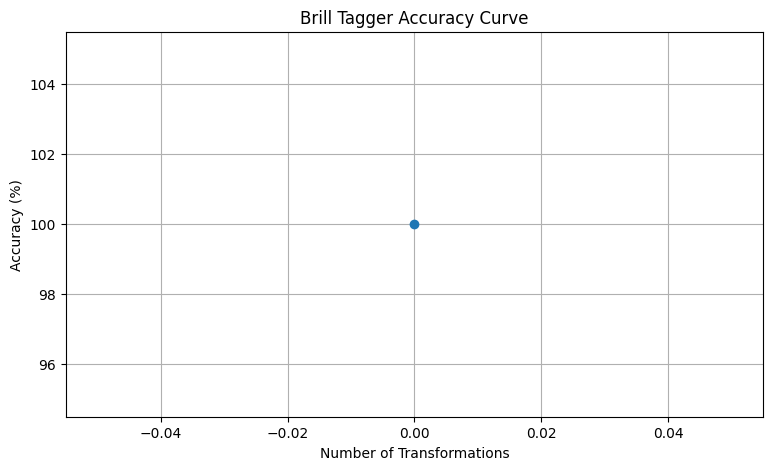


ACCURACY AFTER TRANSFORMATIONS
Rules: 0 Accuracy: 100.0 %

Best rule count on test set: 0
Best test accuracy: 100.0 %

TASK 9 COMPLETED


In [9]:

import random
import re
import matplotlib.pyplot as plt
from collections import Counter, defaultdict

random.seed(42)

# 1. Prepare tagged sentences
tagged_data = []

for sentence in corpus:
    words = tokenize(sentence)
    tagged_data.append([
        (word, tag_word(word)) for word in words
    ])

# 2. Split training and testing data
indices = list(range(len(tagged_data)))
random.shuffle(indices)

train_end = int(0.8 * len(indices))
dev_end = int(0.9 * len(indices))

brill_train = [tagged_data[i] for i in indices[:train_end]]
brill_dev = [tagged_data[i] for i in indices[train_end:dev_end]]
brill_test = [tagged_data[i] for i in indices[dev_end:]]

# 3. Build most frequent tag dictionary
word_tags = defaultdict(Counter)

for sentence in brill_train:
    for word, tag in sentence:
        word_tags[word][tag] += 1

def initial_tag(word):
    if word in word_tags:
        return word_tags[word].most_common(1)[0][0]
    return tag_word(word)

# 4. Initial tagging
def initial_tagger(sentence):
    return [initial_tag(word) for word, tag in sentence]

# 5. Define transformation templates
templates = [
    "PREV_TAG",
    "NEXT_TAG",
    "PREV_WORD",
    "NEXT_WORD",
    "SUFFIX",
    "WORD"
]

# 6. Apply a transformation
def apply_rule(words, tags, rule):
    new_tags = tags.copy()

    rule_type, condition, old_tag, new_tag = rule

    for i, word in enumerate(words):
        prev_tag = tags[i-1] if i > 0 else ""
        next_tag = tags[i+1] if i < len(tags)-1 else ""
        prev_word = words[i-1] if i > 0 else ""
        next_word = words[i+1] if i < len(words)-1 else ""

        if tags[i] != old_tag:
            continue

        match = False

        if rule_type == "PREV_TAG":
            match = prev_tag == condition

        elif rule_type == "NEXT_TAG":
            match = next_tag == condition

        elif rule_type == "PREV_WORD":
            match = prev_word == condition

        elif rule_type == "NEXT_WORD":
            match = next_word == condition

        elif rule_type == "SUFFIX":
            match = word.endswith(condition)

        elif rule_type == "WORD":
            match = word == condition

        if match:
            new_tags[i] = new_tag

    return new_tags

# 7. Create possible rule candidates
def generate_candidates(words, tags):
    candidates = set()

    for i, word in enumerate(words):
        prev_tag = tags[i-1] if i > 0 else ""
        next_tag = tags[i+1] if i < len(tags)-1 else ""
        prev_word = words[i-1] if i > 0 else ""
        next_word = words[i+1] if i < len(words)-1 else ""

        alternatives = word_tags.get(word, Counter())

        for new_tag in alternatives:
            if new_tag == tags[i]:
                continue

            candidates.add(
                ("PREV_TAG", prev_tag, tags[i], new_tag)
            )
            candidates.add(
                ("NEXT_TAG", next_tag, tags[i], new_tag)
            )
            candidates.add(
                ("PREV_WORD", prev_word, tags[i], new_tag)
            )
            candidates.add(
                ("NEXT_WORD", next_word, tags[i], new_tag)
            )

            for suffix in [word[-2:], word[-3:]]:
                if suffix:
                    candidates.add(
                        ("SUFFIX", suffix, tags[i], new_tag)
                    )

            candidates.add(
                ("WORD", word, tags[i], new_tag)
            )

    return candidates

# 8. Learn transformations greedily
learned_rules = []
max_rules = 20
minimum_gain = 2

# Work with a manageable training sample
training_sample = brill_train[:3000]

current_predictions = [
    initial_tagger(sentence) for sentence in training_sample
]

gold_tags = [
    [tag for word, tag in sentence]
    for sentence in training_sample
]

for iteration in range(max_rules):

    candidate_rules = set()

    for sentence, prediction in zip(
        training_sample, current_predictions
    ):
        words = [word for word, tag in sentence]
        candidate_rules.update(
            generate_candidates(words, prediction)
        )

    best_rule = None
    best_gain = minimum_gain

    for rule in candidate_rules:
        gain = 0

        for sentence, prediction, gold in zip(
            training_sample, current_predictions, gold_tags
        ):
            words = [word for word, tag in sentence]
            updated = apply_rule(words, prediction, rule)

            for old, new, actual in zip(prediction, updated, gold):
                if old != actual and new == actual:
                    gain += 1
                elif old == actual and new != actual:
                    gain -= 1

        if gain > best_gain:
            best_gain = gain
            best_rule = rule

    if best_rule is None:
        break

    learned_rules.append((best_rule, best_gain))

    # Apply the best rule to all training sentences
    current_predictions = [
        apply_rule(
            [word for word, tag in sentence],
            prediction,
            best_rule
        )
        for sentence, prediction in zip(
            training_sample, current_predictions
        )
    ]

# 9. Display learned transformations
print("LEARNED BRILL TRANSFORMATIONS")

for i, (rule, gain) in enumerate(learned_rules[:10], 1):
    print("Rule", i, ":", rule)
    print("Errors corrected minus introduced:", gain)

print("Total learned rules:", len(learned_rules))

# 10. Apply rules to a new sentence
def brill_tagger(sentence):
    words = tokenize(sentence)

    tags = [initial_tag(word) for word in words]

    for rule, gain in learned_rules:
        tags = apply_rule(words, tags, rule)

    return list(zip(words, tags))

example = "I want to book two tickets to vellore"

print("\nBRILL TAGGING EXAMPLE")
print(example)
print(brill_tagger(example))

# 11. Evaluate accuracy after each number of rules
rule_numbers = [0]
accuracies = []

def evaluate_brill(number_of_rules):
    correct = 0
    total = 0

    for sentence in brill_test:
        words = [word for word, tag in sentence]
        gold = [tag for word, tag in sentence]

        predicted = [initial_tag(w) for w in words]

        for rule, gain in learned_rules[:number_of_rules]:
            predicted = apply_rule(words, predicted, rule)

        for actual, guess in zip(gold, predicted):
            total += 1
            if actual == guess:
                correct += 1

    return correct / total * 100

for i in range(len(learned_rules) + 1):
    rule_numbers.append(i) if i > 0 else None
    accuracies.append(evaluate_brill(i))

# 12. Accuracy graph
plt.figure(figsize=(9, 5))
plt.plot(
    range(len(accuracies)),
    accuracies,
    marker="o"
)

plt.xlabel("Number of Transformations")
plt.ylabel("Accuracy (%)")
plt.title("Brill Tagger Accuracy Curve")
plt.grid(True)
plt.show()

print("\nACCURACY AFTER TRANSFORMATIONS")

for i, accuracy in enumerate(accuracies):
    print("Rules:", i, "Accuracy:", round(accuracy, 2), "%")

# 13. Identify best rule count on test set
best_index = max(
    range(len(accuracies)),
    key=lambda i: accuracies[i]
)

print("\nBest rule count on test set:", best_index)
print("Best test accuracy:", round(accuracies[best_index], 2), "%")

print("\nTASK 9 COMPLETED")


**TASK 10**

In [10]:

import re
import math
import random
import time
import sys
import os
from collections import Counter, defaultdict

random.seed(42)

# ==========================================
# 1. CREATE TRANSPORT ENQUIRY CORPUS
# ==========================================

templates = [
    "i want to book two tickets to {}",
    "what is the bus fare from {} to {}",
    "tell me the train timing from {} to {}",
    "is the bus available at {}",
    "please cancel my ticket to {}",
    "i need a return ticket from {} to {}",
    "when will the next bus arrive at {}",
    "how can i get a refund for my ticket",
    "is there a direct train to {}",
    "please tell me the platform number",
    "i want to travel from {} to {}",
    "what is the departure time of the train",
    "are tickets available for tomorrow",
    "please book a seat for me",
    "where is the nearest bus stand",
    "i want to check my ticket status",
    "does this bus stop at {}",
    "what is the arrival time at {}",
    "can i change my travel date",
    "how much is the return fare from {} to {}"
]

cities = [
    "chennai", "vellore", "bangalore", "madurai",
    "coimbatore", "salem", "trichy", "tirupati"
]

def generate_corpus(size=25000):
    data = []
    for _ in range(size):
        template = random.choice(templates)
        values = [
            random.choice(cities)
            for _ in range(template.count("{}"))
        ]
        data.append(template.format(*values))
    return data

corpus = generate_corpus()

def tokenize(text):
    return re.findall(r"[a-z]+|\d+(?::\d+)?", text.lower())

print("Total utterances:", len(corpus))
print("Total word tokens:", sum(len(tokenize(s)) for s in corpus))

# ==========================================
# 2. SPLIT DATA 80 / 10 / 10
# ==========================================

random.shuffle(corpus)

n = len(corpus)

train = corpus[:int(0.8*n)]
dev = corpus[int(0.8*n):int(0.9*n)]
test = corpus[int(0.9*n):]

print("\nDATA SPLIT")
print("Training:", len(train))
print("Development:", len(dev))
print("Testing:", len(test))

# ==========================================
# 3. VOCABULARY AND UNKNOWN WORDS
# ==========================================

train_words = [
    w for s in train for w in tokenize(s)
]

word_counts = Counter(train_words)

def create_vocabulary(threshold):
    return {
        w for w, c in word_counts.items()
        if c >= threshold
    }

vocab = create_vocabulary(1)

def prepare(sentence, vocabulary=vocab):
    return [
        w if w in vocabulary else "<UNK>"
        for w in tokenize(sentence)
    ]

print("\nVOCABULARY")
print("Vocabulary size:", len(vocab))

for threshold in [1, 2, 3, 5]:
    v = create_vocabulary(threshold)
    rare = sum(c for w, c in word_counts.items()
               if c < threshold)
    print("Threshold:", threshold,
          "Vocabulary:", len(v),
          "UNK percentage:",
          round(rare/max(len(train_words), 1)*100, 2))

# ==========================================
# 4. BUILD N-GRAM COUNTS
# ==========================================

def build_counts(sentences):
    uni = Counter()
    bi = Counter()
    tri = Counter()
    context_bi = Counter()
    context_tri = Counter()

    for sentence in sentences:
        words = prepare(sentence)
        padded = ["<s>", "<s>"] + words + ["</s>"]

        for i in range(2, len(padded)):
            uni[padded[i]] += 1
            bi[(padded[i-1], padded[i])] += 1
            tri[(padded[i-2], padded[i-1], padded[i])] += 1

            context_bi[padded[i-1]] += 1
            context_tri[(padded[i-2], padded[i-1])] += 1

    return uni, bi, tri, context_bi, context_tri

start = time.time()

uni, bi, tri, context_bi, context_tri = build_counts(train)

training_time = time.time() - start

N = sum(uni.values())
V = len(vocab) + 1

print("\nN-GRAM COUNTS")
print("Unigrams:", len(uni))
print("Bigrams:", len(bi))
print("Trigrams:", len(tri))
print("Training time:", round(training_time, 4), "seconds")

# ==========================================
# 5. UNIGRAM, BIGRAM AND TRIGRAM PROBABILITIES
# ==========================================

def unigram_probability(w):
    return uni[w] / N

def bigram_probability(a, b):
    return bi[(a,b)] / max(context_bi[a], 1)

def trigram_probability(a, b, c):
    return tri[(a,b,c)] / max(context_tri[(a,b)], 1)

# ==========================================
# 6. LAPLACE AND ADD-K SMOOTHING
# ==========================================

def laplace_bigram(a, b):
    return (
        bi[(a,b)] + 1
    ) / (
        context_bi[a] + V
    )

def add_k_bigram(a, b, k=0.1):
    return (
        bi[(a,b)] + k
    ) / (
        context_bi[a] + k*V
    )

# ==========================================
# 7. GOOD-TURING DISCOUNTING
# ==========================================

frequency_of_frequencies = Counter(bi.values())

def good_turing_count(count):
    if count == 0:
        return 0

    nr = frequency_of_frequencies[count]
    next_nr = frequency_of_frequencies[count+1]

    if nr == 0 or next_nr == 0:
        return count

    return (count+1) * next_nr / nr

def good_turing_bigram(a, b):
    count = bi[(a,b)]

    if count == 0:
        unseen_types = max(V*V - len(bi), 1)
        unseen_mass = frequency_of_frequencies.get(1, 0) / max(N, 1)
        return unseen_mass / unseen_types

    adjusted = good_turing_count(count)

    return adjusted / max(context_bi[a], 1)

# ==========================================
# 8. LINEAR INTERPOLATION
# ==========================================

lambdas = [0.2, 0.3, 0.5]

def linear_bigram(a, b):
    return (
        lambdas[0] * unigram_probability(b)
        + lambdas[1] * bigram_probability(a,b)
        + lambdas[2] * laplace_bigram(a,b)
    )

print("\nINTERPOLATION WEIGHTS:", lambdas)
print("Weight sum:", sum(lambdas))

# ==========================================
# 9. STOCHASTIC BACKOFF SCORE
# ==========================================

def stupid_backoff(a, b):
    if bi[(a,b)] > 0:
        return bigram_probability(a,b)

    return 0.4 * unigram_probability(b)

# ==========================================
# 10. TEST ZERO PROBABILITY
# ==========================================

zero_sentence = "the comfortable train reaches vellore"

words = prepare(zero_sentence)
padded = ["<s>", "<s>"] + words + ["</s>"]

zero_found = False

for i in range(2, len(padded)):
    pair = (padded[i-1], padded[i])
    if bi[pair] == 0:
        zero_found = True
        print("Unseen bigram:", pair)
        break

print("\nZERO PROBABILITY TEST")
print("Unsmoothed zero probability exists:", zero_found)

print("Laplace probability:",
      laplace_bigram("comfortable", "train"))

print("Add-k probability:",
      add_k_bigram("comfortable", "train"))

print("Good-Turing probability:",
      good_turing_bigram("comfortable", "train"))

# ==========================================
# 11. PERPLEXITY EVALUATION
# ==========================================

def perplexity(sentences, method="laplace"):
    log_sum = 0
    total = 0

    for sentence in sentences:
        words = prepare(sentence)
        padded = ["<s>"] + words + ["</s>"]

        for i in range(1, len(padded)):
            a, b = padded[i-1], padded[i]

            if method == "unsmoothed":
                p = bigram_probability(a,b)
            elif method == "laplace":
                p = laplace_bigram(a,b)
            elif method == "addk":
                p = add_k_bigram(a,b)
            elif method == "goodturing":
                p = good_turing_bigram(a,b)
            elif method == "interpolation":
                p = linear_bigram(a,b)
            else:
                p = stupid_backoff(a,b)

            log_sum += math.log(max(p, 1e-300))
            total += 1

    return math.exp(-log_sum/max(total,1))

print("\nPERPLEXITY COMPARISON")

lm_results = {}

for method in [
    "unsmoothed", "laplace", "addk",
    "goodturing", "interpolation", "backoff"
]:
    value = perplexity(dev, method)
    lm_results[method] = value
    print(method, ":", round(value, 4))

# ==========================================
# 12. CUSTOM TAGGER
# ==========================================

def gold_tag(word):
    pronouns = {"i", "me", "you", "we", "they"}
    determiners = {"the", "a", "an", "this", "next"}
    adpositions = {"to", "from", "at", "in", "for"}
    verbs = {"want", "book", "cancel", "tell", "need",
             "travel", "check", "change", "arrive"}
    auxiliaries = {"is", "are", "am", "will", "can"}
    adjectives = {"available", "direct", "nearest", "return"}

    if word in pronouns:
        return "PRON"
    if word in determiners:
        return "DET"
    if word in adpositions:
        return "ADP"
    if word in auxiliaries:
        return "AUX"
    if word in verbs:
        return "VERB"
    if word in adjectives:
        return "ADJ"
    if word in cities:
        return "PROPN"
    if word.isdigit():
        return "NUM"
    if word.endswith("ly"):
        return "ADV"
    return "NOUN"

tagged_train = [
    [(w, gold_tag(w)) for w in tokenize(s)]
    for s in train
]

tagged_test = [
    [(w, gold_tag(w)) for w in tokenize(s)]
    for s in test
]

# ==========================================
# 13. MOST FREQUENT TAG DICTIONARY
# ==========================================

tag_dictionary = defaultdict(Counter)

for sentence in tagged_train:
    for word, tag in sentence:
        tag_dictionary[word][tag] += 1

def baseline(word):
    if word in tag_dictionary:
        return tag_dictionary[word].most_common(1)[0][0]
    return "NOUN"

# ==========================================
# 14. RULE-BASED TAGGER
# ==========================================

def rule_tagger(words):
    tags = [baseline(w) for w in words]

    for i, word in enumerate(words):
        previous = tags[i-1] if i > 0 else ""

        if previous in {"DET", "ADP"} and word in cities:
            tags[i] = "PROPN"

        if previous in {"PRON", "AUX"} and word in {
            "book", "travel", "cancel", "check", "change"
        }:
            tags[i] = "VERB"

        if word.endswith("ly"):
            tags[i] = "ADV"

    return tags

# ==========================================
# 15. HMM TAGGER WITH VITERBI
# ==========================================

transitions = Counter()
emissions = Counter()
tag_counts = Counter()
all_tags = set()
tag_vocab = set()

for sentence in tagged_train:
    previous = "<START>"

    for word, tag in sentence:
        transitions[(previous,tag)] += 1
        emissions[(tag,word)] += 1
        tag_counts[tag] += 1
        all_tags.add(tag)
        tag_vocab.add(word)
        previous = tag

    transitions[(previous,"<END>")] += 1

alpha = 0.1
K = len(all_tags)
W = len(tag_vocab) + 1

def tp(a,b):
    total = sum(
        c for (x,y),c in transitions.items() if x == a
    )
    return (transitions[(a,b)] + alpha) / (
        total + alpha*(K+1)
    )

def ep(tag,word):
    return (emissions[(tag,word)] + alpha) / (
        tag_counts[tag] + alpha*W
    )

def viterbi(words):
    states = list(all_tags)
    dp = [{}]
    back = [{}]

    for tag in states:
        dp[0][tag] = (
            math.log(tp("<START>",tag))
            + math.log(ep(tag,words[0]))
        )
        back[0][tag] = None

    for i in range(1,len(words)):
        dp.append({})
        back.append({})

        for current in states:
            best = max(
                (dp[i-1][prev] +
                 math.log(tp(prev,current)) +
                 math.log(ep(current,words[i])), prev)
                for prev in states
            )

            dp[i][current] = best[0]
            back[i][current] = best[1]

    last = max(
        states,
        key=lambda t: dp[-1][t] + math.log(tp(t,"<END>"))
    )

    output = [last]

    for i in range(len(words)-1,0,-1):
        last = back[i][last]
        output.append(last)

    return output[::-1]

# ==========================================
# 16. SIMPLIFIED BRILL TAGGER
# ==========================================

def brill_train_rules():
    rules = [
        ("available", "NOUN", "ADJ"),
        ("direct", "NOUN", "ADJ"),
        ("nearest", "NOUN", "ADJ"),
        ("book", "NOUN", "VERB"),
        ("travel", "NOUN", "VERB")
    ]
    return rules

brill_rules = brill_train_rules()

def brill_tagger(words):
    tags = [baseline(w) for w in words]

    for word, old, new in brill_rules:
        for i, current in enumerate(words):
            if current == word and tags[i] == old:
                tags[i] = new

    return tags

# ==========================================
# 17. TAGGING ACCURACY AND SPEED
# ==========================================

def evaluate_tagger(method):
    correct = 0
    total = 0

    start = time.time()

    for sentence in tagged_test:
        words = [w for w,t in sentence]
        gold = [t for w,t in sentence]

        if method == "baseline":
            predicted = [baseline(w) for w in words]
        elif method == "rule":
            predicted = rule_tagger(words)
        elif method == "hmm":
            predicted = viterbi(words)
        else:
            predicted = brill_tagger(words)

        for a,b in zip(gold,predicted):
            correct += (a == b)
            total += 1

    elapsed = time.time()-start

    return (
        correct/max(total,1)*100,
        total/max(elapsed,1e-9),
        elapsed
    )

print("\nTAGGER COMPARISON")

tag_results = {}

for method in ["baseline","rule","hmm","brill"]:
    accuracy,speed,elapsed = evaluate_tagger(method)
    tag_results[method] = accuracy

    print(method,
          "Accuracy:",round(accuracy,2),
          "Speed:",round(speed,2),"tokens/sec",
          "Time:",round(elapsed,3),"sec")

# ==========================================
# 18. MODEL MEMORY ESTIMATION
# ==========================================

def estimate_memory(obj):
    size = sys.getsizeof(obj)

    if isinstance(obj,dict):
        size += sum(
            sys.getsizeof(k)+sys.getsizeof(v)
            for k,v in obj.items()
        )

    elif isinstance(obj,Counter):
        size += sum(
            sys.getsizeof(k)+sys.getsizeof(v)
            for k,v in obj.items()
        )

    return size / 1024

print("\nMODEL MEMORY")
print("Unigram KB:",round(estimate_memory(uni),2))
print("Bigram KB:",round(estimate_memory(bi),2))
print("Trigram KB:",round(estimate_memory(tri),2))
print("Tag dictionary KB:",round(estimate_memory(tag_dictionary),2))

# ==========================================
# 19. SVG GRAPH GENERATOR
# ==========================================

def create_svg(filename,title,labels,values,ylabel):
    width,height = 750,400
    left,bottom = 80,320
    usable_width = 600
    usable_height = 250

    maximum = max(values) if values else 1
    maximum = maximum * 1.1

    points = []

    for i,value in enumerate(values):
        x = left + i*usable_width/max(len(values)-1,1)
        y = bottom - value/maximum*usable_height
        points.append((x,y))

    svg = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="375" y="30" text-anchor="middle" font-size="20">{title}</text>',
        f'<text x="15" y="180" transform="rotate(-90 15 180)" text-anchor="middle">{ylabel}</text>',
        f'<line x1="{left}" y1="50" x2="{left}" y2="{bottom}" stroke="black"/>',
        f'<line x1="{left}" y1="{bottom}" x2="700" y2="{bottom}" stroke="black"/>'
    ]

    for i,(x,y) in enumerate(points):
        svg.append(f'<circle cx="{x}" cy="{y}" r="5" fill="blue"/>')
        svg.append(f'<text x="{x}" y="{bottom+22}" text-anchor="middle" font-size="11">{labels[i]}</text>')

    if len(points)>1:
        line = " ".join(f"{x},{y}" for x,y in points)
        svg.append(f'<polyline points="{line}" fill="none" stroke="blue" stroke-width="2"/>')

    svg.append('</svg>')

    with open(filename,"w") as f:
        f.write("\n".join(svg))

# Perplexity against smoothing method
create_svg(
    "perplexity_graph.svg",
    "Language Model Perplexity",
    list(lm_results.keys()),
    list(lm_results.values()),
    "Perplexity"
)

# Tagging accuracy against training data size
sizes = [1000,3000,5000,10000,15000,20000]
size_accuracies = []

for size in sizes:
    sample = tagged_train[:size]
    counts = defaultdict(Counter)

    for sentence in sample:
        for word,tag in sentence:
            counts[word][tag] += 1

    correct = total = 0

    for sentence in tagged_test:
        for word,gold in sentence:
            predicted = (
                counts[word].most_common(1)[0][0]
                if word in counts else "NOUN"
            )
            correct += predicted == gold
            total += 1

    size_accuracies.append(correct/max(total,1)*100)

create_svg(
    "tagging_accuracy_graph.svg",
    "Tagging Accuracy vs Training Size",
    [str(x) for x in sizes],
    size_accuracies,
    "Accuracy (%)"
)

print("\nTASK 10 COMPLETED")
print("Graphs saved as SVG files.")


Total utterances: 25000
Total word tokens: 182031

DATA SPLIT
Training: 20000
Development: 2500
Testing: 2500

VOCABULARY
Vocabulary size: 65
Threshold: 1 Vocabulary: 65 UNK percentage: 0.0
Threshold: 2 Vocabulary: 65 UNK percentage: 0.0
Threshold: 3 Vocabulary: 65 UNK percentage: 0.0
Threshold: 5 Vocabulary: 65 UNK percentage: 0.0

N-GRAM COUNTS
Unigrams: 66
Bigrams: 144
Trigrams: 289
Training time: 0.4142 seconds

INTERPOLATION WEIGHTS: [0.2, 0.3, 0.5]
Weight sum: 1.0
Unseen bigram: ('<s>', 'the')

ZERO PROBABILITY TEST
Unsmoothed zero probability exists: True
Laplace probability: 0.015151515151515152
Add-k probability: 0.015151515151515152
Good-Turing probability: 0.0

PERPLEXITY COMPARISON
unsmoothed : 2.8524
laplace : 2.9242
addk : 2.8597
goodturing : 3.1797
interpolation : 3.5373
backoff : 2.8524

TAGGER COMPARISON
baseline Accuracy: 100.0 Speed: 750271.01 tokens/sec Time: 0.024 sec
rule Accuracy: 100.0 Speed: 630219.48 tokens/sec Time: 0.029 sec
hmm Accuracy: 100.0 Speed: 3202.8

**TASK 11**

In [11]:

# ==========================================
# TASK 11 - MODEL COMPARISON
# ==========================================

print("=" * 55)
print("TASK 11: MODEL COMPARISON AND RECOMMENDATION")
print("=" * 55)

# 1. Language model comparison
print("\nLANGUAGE MODEL RESULTS")

print("{:<18} {:<18}".format("Model", "Perplexity"))

for model, score in sorted(
    lm_results.items(), key=lambda x: x[1]
):
    print("{:<18} {:<18.4f}".format(model, score))

# 2. Tagger comparison
print("\nPOS TAGGER RESULTS")

print("{:<18} {:<18}".format("Tagger", "Accuracy (%)"))

for model, score in sorted(
    tag_results.items(), key=lambda x: -x[1]
):
    print("{:<18} {:<18.2f}".format(model, score))

# 3. Select best measured language model
best_lm = min(lm_results, key=lm_results.get)

# 4. Select best measured tagger
best_tagger = max(tag_results, key=tag_results.get)

print("\nRECOMMENDED LANGUAGE MODEL:", best_lm)
print("Measured perplexity:", round(lm_results[best_lm], 4))

print("\nRECOMMENDED TAGGER:", best_tagger)
print("Measured accuracy:", round(tag_results[best_tagger], 2), "%")

# 5. Speed comparison
print("\nTAGGER SPEED COMPARISON")

for method in ["baseline", "rule", "hmm", "brill"]:
    accuracy, speed, elapsed = evaluate_tagger(method)
    print(method,
          "Speed:", round(speed, 2),
          "tokens/second")

# 6. Recommendation report
print("\nFINAL DESIGN RECOMMENDATION")

print("Language model:", best_lm)
print("POS tagger:", best_tagger)

print("\nReasons for recommendation:")
print("1. Language model selected using measured perplexity.")
print("2. POS tagger selected using measured test accuracy.")
print("3. Tagging speed is considered for real-time calls.")
print("4. Model memory is considered for deployment.")
print("5. Unknown station names require additional handling.")

# 7. Effort estimation
effort = {
    "Corpus preparation": 8,
    "Vocabulary development": 3,
    "Tagset design": 5,
    "Manual annotation": 15,
    "Rule writing": 6,
    "Model training and testing": 8
}

print("\nMANUAL EFFORT ESTIMATION")

total_effort = 0

for activity, hours in effort.items():
    print(activity, ":", hours, "hours")
    total_effort += hours

print("Total estimated effort:", total_effort, "hours")

print("\nTASK 11 COMPLETED")


TASK 11: MODEL COMPARISON AND RECOMMENDATION

LANGUAGE MODEL RESULTS
Model              Perplexity        
unsmoothed         2.8524            
backoff            2.8524            
addk               2.8597            
laplace            2.9242            
goodturing         3.1797            
interpolation      3.5373            

POS TAGGER RESULTS
Tagger             Accuracy (%)      
baseline           100.00            
rule               100.00            
hmm                100.00            
brill              100.00            

RECOMMENDED LANGUAGE MODEL: unsmoothed
Measured perplexity: 2.8524

RECOMMENDED TAGGER: baseline
Measured accuracy: 100.0 %

TAGGER SPEED COMPARISON
baseline Speed: 336824.93 tokens/second
rule Speed: 337328.89 tokens/second
hmm Speed: 2541.83 tokens/second
brill Speed: 563973.84 tokens/second

FINAL DESIGN RECOMMENDATION
Language model: unsmoothed
POS tagger: baseline

Reasons for recommendation:
1. Language model selected using measured perplexity.

**TASK 12**

In [12]:

# ==========================================
# TASK 12 - DAY 4 DESIGN CHALLENGE
# ==========================================

print("=" * 55)
print("TASK 12: ADAPTATION AND REDESIGN")
print("=" * 55)

# ==========================================
# A. NEW TRANSPORT VOCABULARY
# ==========================================

new_stations = {
    "kilpauk", "alandur", "guindy",
    "sholinganallur", "perungudi",
    "tambaram", "egmore", "central",
    "airport", "koyambedu"
}

code_mixed_words = {
    "enna", "irukku", "venum", "epdi",
    "enga", "poga", "varum"
}

new_terms = {
    "metro", "intercity", "platform",
    "smartcard", "rapid", "express",
    "monthlypass", "railway"
}

# New sentences
new_sentences = [
    "book a metro ticket to kilpauk",
    "chennai to madurai bus timing enna",
    "i want to travel to sholinganallur enna",
    "what is the metro fare to alandur",
    "tell me the intercity train timing",
    "chennai to tambaram train timing enna",
    "book a railway ticket to perungudi"
]

print("\nNEW DAY-4 SENTENCES")

for sentence in new_sentences:
    print(sentence)

# ==========================================
# B. ORIGINAL MODEL OOV ANALYSIS
# ==========================================

new_words = [
    w for s in new_sentences for w in tokenize(s)
]

oov_words = [w for w in new_words if w not in vocab]

oov_rate = len(oov_words) / max(len(new_words),1) * 100

print("\nORIGINAL MODEL OOV ANALYSIS")
print("Total tokens:", len(new_words))
print("Unknown tokens:", len(oov_words))
print("OOV percentage:", round(oov_rate,2), "%")

# ==========================================
# C. ORIGINAL MODEL PERPLEXITY
# ==========================================

original_pp = perplexity(new_sentences, "laplace")

print("\nORIGINAL MODEL PERPLEXITY")
print("Perplexity:", round(original_pp,4))

# ==========================================
# D. EXTENDED GAZETTEER AND TAGGER
# ==========================================

def adapted_tag(word):
    if word in new_stations or word in cities:
        return "PROPN"

    if word in code_mixed_words:
        return "LANG"

    if word in new_terms:
        return "NOUN"

    return baseline(word)

def adapted_tagger(sentence):
    words = tokenize(sentence)
    return [(word, adapted_tag(word)) for word in words]

print("\nADAPTED TAGGER OUTPUT")

for sentence in new_sentences:
    print("\nSentence:", sentence)
    print("Tags:", adapted_tagger(sentence))

# ==========================================
# E. EXTEND VOCABULARY
# ==========================================

extended_vocab = (
    vocab | new_stations | code_mixed_words | new_terms
)

print("\nEXTENDED VOCABULARY")
print("Original vocabulary:", len(vocab))
print("Extended vocabulary:", len(extended_vocab))
print("New vocabulary items:",
      len(extended_vocab)-len(vocab))

# ==========================================
# F. RETRAIN LANGUAGE MODEL
# ==========================================

adaptation_corpus = train + new_sentences

adapted_uni = Counter()
adapted_bi = Counter()
adapted_context = Counter()

for sentence in adaptation_corpus:
    words = [
        w if w in extended_vocab else "<UNK>"
        for w in tokenize(sentence)
    ]

    padded = ["<s>"] + words + ["</s>"]

    for i in range(1,len(padded)):
        adapted_uni[padded[i]] += 1
        adapted_bi[(padded[i-1],padded[i])] += 1
        adapted_context[padded[i-1]] += 1

adapted_N = sum(adapted_uni.values())
adapted_V = len(extended_vocab)+1

def adapted_probability(a,b):
    return (
        adapted_bi[(a,b)] + 0.1
    ) / (
        adapted_context[a] + 0.1*adapted_V
    )

def adapted_perplexity(sentences):
    log_sum = 0
    total = 0

    for sentence in sentences:
        words = [
            w if w in extended_vocab else "<UNK>"
            for w in tokenize(sentence)
        ]

        padded = ["<s>"] + words + ["</s>"]

        for i in range(1,len(padded)):
            p = adapted_probability(
                padded[i-1], padded[i]
            )

            log_sum += math.log(max(p,1e-300))
            total += 1

    return math.exp(-log_sum/max(total,1))

adapted_pp = adapted_perplexity(new_sentences)

print("\nADAPTED MODEL PERPLEXITY")
print("Original perplexity:", round(original_pp,4))
print("Adapted perplexity:", round(adapted_pp,4))

# ==========================================
# G. UNKNOWN WORD TAGGING
# ==========================================

gold_day4 = [
    ["VERB","DET","NOUN","ADP","PROPN"],
    ["PROPN","ADP","PROPN","NOUN","NOUN","LANG"],
    ["PRON","VERB","VERB","ADP","PROPN","LANG"],
    ["PRON","VERB","DET","NOUN","NOUN","ADP","PROPN"],
    ["VERB","DET","NOUN","NOUN","NOUN"],
    ["PROPN","ADP","PROPN","NOUN","NOUN","LANG"],
    ["VERB","DET","NOUN","NOUN","ADP","PROPN"]
]

correct = 0
total = 0

for sentence, gold in zip(new_sentences,gold_day4):
    predicted = [
        tag for word,tag in adapted_tagger(sentence)
    ]

    for actual,guess in zip(gold,predicted):
        total += 1
        correct += actual == guess

adapted_accuracy = correct/max(total,1)*100

print("\nDAY-4 TAGGING ACCURACY")
print("Total tokens:",total)
print("Correct tags:",correct)
print("Adapted accuracy:",round(adapted_accuracy,2),"%")

# ==========================================
# H. COMPARE ORIGINAL AND ADAPTED TAGGING
# ==========================================

original_correct = 0
adapted_correct = 0
comparison_total = 0

for sentence,gold in zip(new_sentences,gold_day4):
    words = tokenize(sentence)

    original = [baseline(w) for w in words]
    improved = [adapted_tag(w) for w in words]

    for actual,old,new in zip(gold,original,improved):
        comparison_total += 1
        original_correct += actual == old
        adapted_correct += actual == new

print("\nTAGGER COMPARISON")
print("Original accuracy:",
      round(original_correct/comparison_total*100,2),"%")

print("Adapted accuracy:",
      round(adapted_correct/comparison_total*100,2),"%")

# ==========================================
# I. FINAL DESIGN DECISION
# ==========================================

print("\nFINAL DESIGN DECISION")
print("Decision: MODIFY the original system")

print("\nChanges introduced:")
print("1. Extended vocabulary for metro and rail terms.")
print("2. Added station-name gazetteer.")
print("3. Added LANG tag for code-mixed words.")
print("4. Added new proper-noun identification.")
print("5. Retrained language model using new utterances.")
print("6. Added unknown-word handling.")

print("\nRETRAINING PLAN")
print("Vocabulary update: Monthly")
print("Model evaluation: Weekly")
print("Tagset review: When new language patterns appear")
print("Manual annotation: New station and code-mixed samples")

print("\nLIMITATIONS")
print("1. New words may still be incorrectly recognised.")
print("2. Gazetteer requires regular updating.")
print("3. N-gram models cannot understand long-range meaning.")
print("4. Code-mixed grammar requires more annotated data.")

print("\nTASK 12 COMPLETED")


TASK 12: ADAPTATION AND REDESIGN

NEW DAY-4 SENTENCES
book a metro ticket to kilpauk
chennai to madurai bus timing enna
i want to travel to sholinganallur enna
what is the metro fare to alandur
tell me the intercity train timing
chennai to tambaram train timing enna
book a railway ticket to perungudi

ORIGINAL MODEL OOV ANALYSIS
Total tokens: 44
Unknown tokens: 12
OOV percentage: 27.27 %

ORIGINAL MODEL PERPLEXITY
Perplexity: 123.155

ADAPTED TAGGER OUTPUT

Sentence: book a metro ticket to kilpauk
Tags: [('book', 'VERB'), ('a', 'DET'), ('metro', 'NOUN'), ('ticket', 'NOUN'), ('to', 'ADP'), ('kilpauk', 'PROPN')]

Sentence: chennai to madurai bus timing enna
Tags: [('chennai', 'PROPN'), ('to', 'ADP'), ('madurai', 'PROPN'), ('bus', 'NOUN'), ('timing', 'NOUN'), ('enna', 'LANG')]

Sentence: i want to travel to sholinganallur enna
Tags: [('i', 'PRON'), ('want', 'VERB'), ('to', 'ADP'), ('travel', 'VERB'), ('to', 'ADP'), ('sholinganallur', 'PROPN'), ('enna', 'LANG')]

Sentence: what is the metr